Homework 2, problem 5, part c

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from noisy_if import isi_from_trace
from noisy_if import isi_first_passage

In [2]:
def simulate(mu = 1.0, theta = 1.0, sigma2 = 0.25, T = 10000, dt = 0.01, transient = 1000, seed = 0):

    rng = np.random.default_rng(seed)

    sigma = np.sqrt(sigma2)

    n = int(T / dt)
    n_transient = int(transient / dt)

    u = 0.0
    spikes = []
    values = []

    for i in range(n):
        t = i * dt

        # Euler-Maruyama
        u += mu * dt + np.sqrt(2 * sigma2 * dt) * rng.standard_normal()

        if u >= theta: # reset after reaching threshold
            if t >= transient:
                spikes.append(t)
            u = 0.0

        if i >= n_transient: # only collect data after transient
            values.append(u)

    values = np.array(values)
    spikes = np.array(spikes)

    # measured firing rate
    rate = len(spikes) / (T - transient)

    # measured fraction of time below reset
    fraction_below = np.mean(values < 0)

    return values, spikes, rate, fraction_below

In [3]:
def theoretical_density(u, mu = 1.0, theta = 1.0, sigma2 = 0.25):

    nu = mu / theta

    p = np.zeros_like(u)

    below = u < 0
    between = (u >= 0) & (u <= theta)

    p[below] = (nu / mu) * (1 - np.exp(-mu * theta / sigma2)) * np.exp(mu * u[below] / sigma2)
    p[between] = (nu / mu) * (1 - np.exp(mu * (u[between] - theta) / sigma2))

    return p

In [4]:
mu = 1.0
theta = 1.0

sigma2_values = [0.25, 1.0, 4.0]

for sigma2 in sigma2_values:

    values, spikes, rate, fraction_below = simulate(
        mu = mu,
        theta = theta,
        sigma2 = sigma2,
        T = 10000,
        dt = 0.01,
        transient = 1000,
        seed = 0
    )

    # theoretical
    rate_theory = mu / theta

    fraction_theory = (sigma2 / (mu * theta) * (1 - np.exp(-mu * theta / sigma2)))

    print(f"sigma^2 = {sigma2}")
    print(f"  measured firing rate = {rate:.4f}")
    print(f"  predicted firing rate = {rate_theory:.4f}")
    print(f"  measured fraction u < 0 = {fraction_below:.4f}")
    print(f"  predicted fraction u < 0 = {fraction_theory:.4f}")
    print()

sigma^2 = 0.25
  measured firing rate = 0.9662
  predicted firing rate = 1.0000
  measured fraction u < 0 = 0.2284
  predicted fraction u < 0 = 0.2454

sigma^2 = 1.0
  measured firing rate = 0.9382
  predicted firing rate = 1.0000
  measured fraction u < 0 = 0.6002
  predicted fraction u < 0 = 0.6321

sigma^2 = 4.0
  measured firing rate = 0.8850
  predicted firing rate = 1.0000
  measured fraction u < 0 = 0.8600
  predicted fraction u < 0 = 0.8848



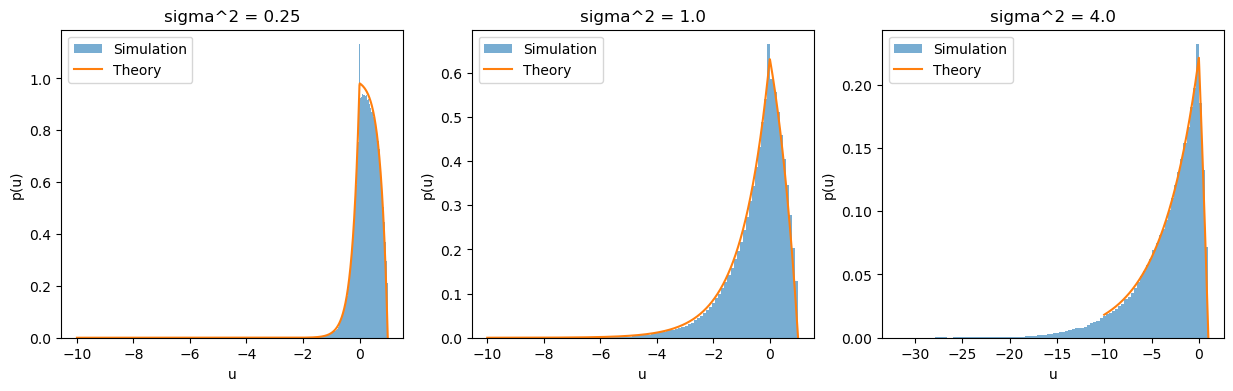

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, sigma2 in zip(axes, sigma2_values):

    values, spikes, rate, fraction_below = simulate(
        mu = 1.0,
        theta = 1.0,
        sigma2 = sigma2,
        T = 10000,
        dt = 0.01,
        transient = 1000,
        seed = 0
    )

    # Histogram of simulated voltage
    ax.hist(
        values,
        bins = 100,
        density = True,
        alpha = 0.6,
        label = "Simulation"
    )

    # Theoretical density
    x = np.linspace(-10, 1, 1000)
    p = theoretical_density(
        x,
        mu = 1.0,
        theta = 1.0,
        sigma2 = sigma2
    )

    ax.plot(x, p, label = "Theory")

    ax.set_title(f"sigma^2 = {sigma2}")
    ax.set_xlabel("u")
    ax.set_ylabel("p(u)")
    ax.legend()

plt.show()